# QA Pipeline Walkthrough — watch the calculations happen

This notebook re-derives, step by step, how the QA triage pipeline turns real
satellite files into a pass / retry / escalate decision — a deterministic
rules engine (`agent/qa_rules.py`), not an LLM or anything making judgment
calls. **Everything runs on the real scenes in `data/`** — the numbers you
see are the same numbers in `agent/decisions.json`.

Run each cell top to bottom. Cells that compute something print the
intermediate steps so you can see *where* every number comes from. At the end
you get to change a QA threshold and watch the decision flip.

> Kernel: use the repo's virtualenv — `python3 -m venv .venv`, then
> `.venv/bin/pip install -r agent/requirements.txt jupyterlab matplotlib ipywidgets`,
> then launch with `.venv/bin/jupyter lab` from the repo root.

## Setup — imports and scene discovery

This cell just wires up paths and lists the real scenes. `ROOT` is detected so
it works whether Jupyter was launched from the repo root or from `notebooks/`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import tifffile
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.dpi"] = 90

# Locate the repo root (works from repo root or from notebooks/)
ROOT = Path.cwd()
if not (ROOT / "agent").exists() and (ROOT.parent / "agent").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "agent"))   # so we can import the QA engine's own modules later

DATA = ROOT / "data"
scenes = sorted(p for p in DATA.iterdir() if (p / "stac_metadata.json").exists())
print("Real scenes found in data/:")
for p in scenes:
    print(f"  - {p.name}")
print(f"\nWe'll start with the interesting one: {scenes[1].name}")

Real scenes found in data/:
  - 01-clean-cropfield-australia
  - 02-wildfire-smoke-saskatchewan
  - 03-copper-mine-chile

We'll start with the interesting one: 02-wildfire-smoke-saskatchewan


## Look at one scene's files

Each scene folder holds the delivered product: the catalog record
(`stac_metadata.json`), human previews (PNGs), and the two **raster masks**
that QA actually reads. Note how small the masks are compared to the preview:
they are per-pixel *labels*, not images.

In [2]:
scene = scenes[1]   # the wildfire-smoke scene
print(scene.name)
for f in sorted(scene.iterdir()):
    print(f"  {f.name:34s} {f.stat().st_size/1024:9.1f} KB")

02-wildfire-smoke-saskatchewan
  data_mask.tiff                        1749.1 KB
  data_mask_preview.png                   30.2 KB
  pixel_quality_mask.tiff               3532.2 KB
  preview.png                           7490.2 KB
  quality_mask_preview.png                 5.6 KB
  stac_metadata.json                      52.1 KB
  thumbnail.png                          562.5 KB


## The data mask — 4 layers of yes/no

`data_mask.tiff` is one raster with **4 bands**, in Wyvern's fixed order:

| band | question | 1 = | 0 = | 255 = |
|---|---|---|---|---|
| 0 | clear? | clear pixel | not clear | NoData |
| 1 | cloud? | cloudy | not cloudy | NoData |
| 2 | haze? | hazy / smoky | not hazy | NoData |
| 3 | cloud-shadow? | shadowed | not shadowed | NoData |

Let's load it and look at the raw numbers.

In [3]:
dm = tifffile.imread(str(scene / "data_mask.tiff"))
print("data mask shape (H, W, B):", dm.shape, " dtype:", dm.dtype)
print("all unique values in the file:", np.unique(dm))
print()
print("band 1 (cloud) — pixel counts per value:")
vals, counts = np.unique(dm[..., 1], return_counts=True)
for v, c in zip(vals, counts):
    print(f"  value {v:3d}: {c:>12,} pixels  ({100*c/dm[..., 1].size:.2f}% of raster)")

data mask shape (H, W, B): (10352, 6719, 4)  dtype: uint8


all unique values in the file: [  0   1 255]

band 1 (cloud) — pixel counts per value:


  value   0:   25,920,085 pixels  (37.27% of raster)
  value   1:   15,785,025 pixels  (22.69% of raster)
  value 255:   27,849,978 pixels  (40.04% of raster)


---
## Seeing the 4 layers in 3D

The table of counts above is correct but abstract. Plotting `(row, column)` as
the base plane and layer index as height turns "4 fixed condition layers" into
something you can actually see: clear / cloud / haze / cloud-shadow each become
their own flat shape, stacked at different heights, all describing the *same*
scene from a different angle.


/var/folders/8n/bgsjrzs53cq41sdmxxq8k6r80000gn/T/ipykernel_21796/726030631.py:26: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


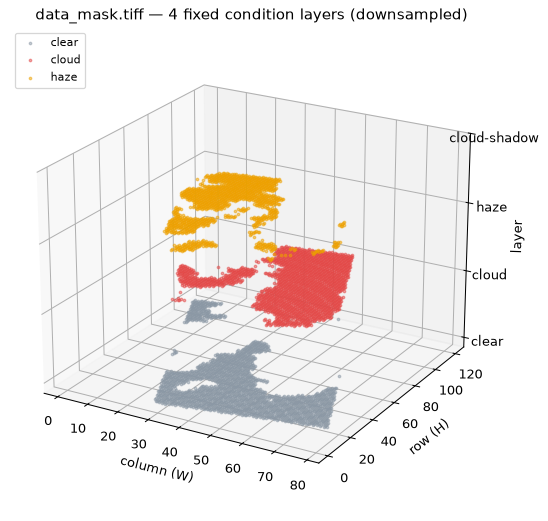

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3d projection)

f3d = max(1, dm.shape[0] // 120)
dm_small = dm[::f3d, ::f3d, :]
H3, W3, B3 = dm_small.shape

labels3 = ["clear", "cloud", "haze", "cloud-shadow"]
colors3 = ["#8b98a5", "#e34948", "#eda100", "#2a78d6"]

yy3, xx3 = np.meshgrid(np.arange(H3), np.arange(W3), indexing="ij")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for b in range(B3):
    present = dm_small[:, :, b] == 1
    if not present.any():
        continue
    ax.scatter(xx3[present], yy3[present], np.full(present.sum(), b),
               c=colors3[b], s=4, alpha=0.5, label=labels3[b], depthshade=False)

ax.set_xlabel("column (W)"); ax.set_ylabel("row (H)"); ax.set_zlabel("layer")
ax.set_zticks(range(B3)); ax.set_zticklabels(labels3)
ax.set_title("data_mask.tiff — 4 fixed condition layers (downsampled)")
ax.legend(loc="upper left", fontsize=9)
ax.view_init(elev=22, azim=-60)
plt.tight_layout(); plt.show()

## The key preprocessing step: the "valid footprint"

The raster is a rectangle, but the scene inside is an angled strip — the rest
is a `255` NoData border (you can see it below as the black border). **Every
QA percentage is computed over the valid footprint only**, so the empty border
can't dilute the numbers. Watch how much of the raster is empty:

raster pixels:          69,555,088
valid footprint:        41,705,110  (59.96% of raster)
empty 255 border:       27,849,978

→ all percentages below use 41,705,110 as the denominator.


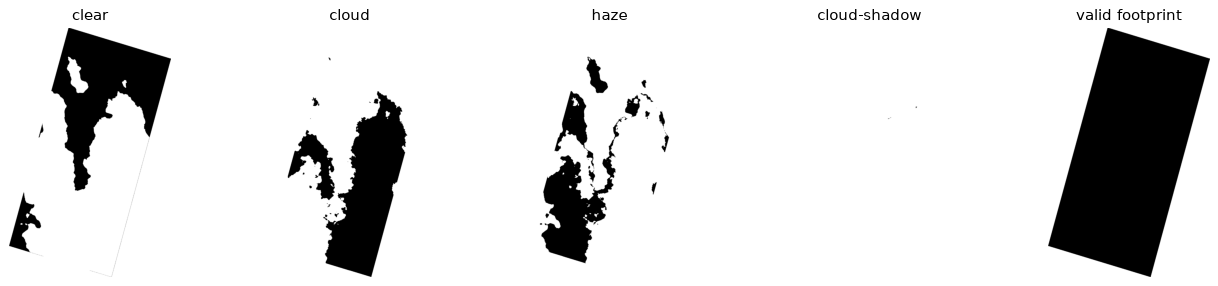

In [5]:
valid = np.any(dm != 255, axis=-1)      # pixel is scene if ANY layer has data
vtot = int(valid.sum())
print(f"raster pixels:        {valid.size:>12,}")
print(f"valid footprint:      {vtot:>12,}  ({100*vtot/valid.size:.2f}% of raster)")
print(f"empty 255 border:     {valid.size - vtot:>12,}")
print(f"\n→ all percentages below use {vtot:,} as the denominator.")

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
titles = ["clear", "cloud", "haze", "cloud-shadow", "valid footprint"]
for i, ax in enumerate(axes[:4]):
    ax.imshow(dm[::8, ::8, i] == 1, cmap="gray_r"); ax.set_title(titles[i]); ax.axis("off")
axes[4].imshow(valid[::8, ::8], cmap="gray_r"); axes[4].set_title(titles[4]); axes[4].axis("off")
plt.show()

---
## Metric 1 — `band_count`

The pixel quality mask has **one layer per spectral band**, so its depth is
the scene's band count. (We also cross-check it against the STAC catalog's
band list.)

In [6]:
pq = tifffile.imread(str(scene / "pixel_quality_mask.tiff"))
print("PQ mask shape (H, W, B):", pq.shape)
band_count = pq.shape[2]
print(f"→ band_count = {band_count}")

meta = json.loads((scene / "stac_metadata.json").read_text())
platform = meta["properties"]["platform"]
stac_bands = len(meta["assets"]["Cloud optimized GeoTiff"]["eo:bands"])
print(f"platform: {platform} | STAC catalog lists {stac_bands} bands")
rules_cfg = json.loads((ROOT / "agent" / "rules.json").read_text())
print(f"expected bands for {platform}: {rules_cfg['platforms'][platform]}")

PQ mask shape (H, W, B): (10352, 6719, 31)
→ band_count = 31
platform: Dragonette-003 | STAC catalog lists 31 bands
expected bands for Dragonette-003: {'expected_bands': 31}


---
## Metric 2 — `cloud_or_haze_pct` (the interesting one)

Cloud and haze/smoke both block the surface, so QA counts a pixel as
obstructed if **either** layer flags it. The `|` (OR, union) matters: a pixel
flagged as both cloud and haze is one obstructed pixel — it must count once,
not twice.

cloud pixels:                   15,785,025   37.85% of valid
haze (smoke) pixels:            10,195,868   24.45% of valid
pixels flagged as BOTH:                  2   (double-counted by a naive +)
cloud OR haze (union):          25,980,891   62.30% of valid

→ cloud_or_haze_pct = 62.3%


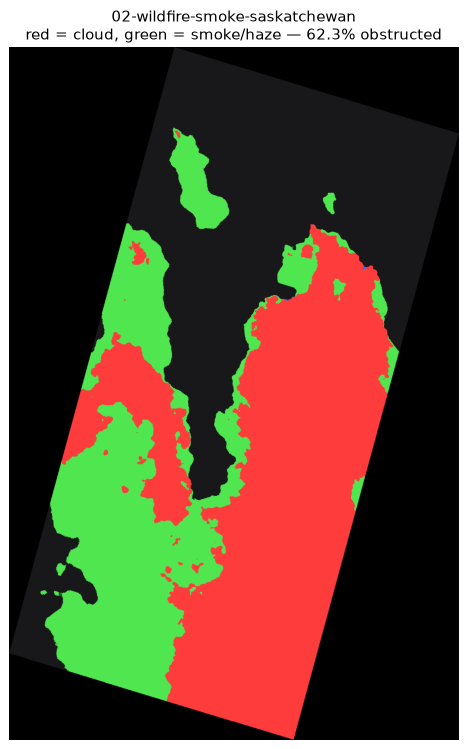

In [7]:
cloud = (dm[..., 1] == 1) & valid
haze  = (dm[..., 2] == 1) & valid
union = cloud | haze
overlap = cloud & haze

print(f"cloud pixels:                 {cloud.sum():>12,}   {100*cloud.sum()/vtot:.2f}% of valid")
print(f"haze (smoke) pixels:          {haze.sum():>12,}   {100*haze.sum()/vtot:.2f}% of valid")
print(f"pixels flagged as BOTH:       {overlap.sum():>12,}   (double-counted by a naive +)")
print(f"cloud OR haze (union):        {union.sum():>12,}   {100*union.sum()/vtot:.2f}% of valid")
cloud_or_haze_pct = round(100 * union.sum() / vtot, 2)
print(f"\n→ cloud_or_haze_pct = {cloud_or_haze_pct}%")

# and the same computation, rendered like the dashboard shows it
def mask_rgb(dm, max_w=1000):
    f = max(1, dm.shape[1] // max_w)
    m = dm[::f, ::f]
    rgb = np.zeros((*m.shape[:2], 3), dtype=np.uint8)
    rgb[m[..., 1] == 1] = (255, 60, 60)     # cloud
    rgb[m[..., 2] == 1] = (80, 230, 80)     # haze/smoke
    rgb[m[..., 3] == 1] = (70, 100, 255)    # shadow
    rgb[(m[..., 0] == 1) & np.all(m != 255, axis=-1)] = (24, 24, 26)  # clear
    rgb[np.all(m == 255, axis=-1)] = (0, 0, 0)                        # outside scene
    return rgb

plt.figure(figsize=(9, 10))
plt.imshow(mask_rgb(dm)); plt.axis("off")
plt.title(f"{scene.name}\nred = cloud, green = smoke/haze — {cloud_or_haze_pct}% obstructed")
plt.show()

---
## Metric 3 — `quality_mask_coverage_pct`

QA can only certify a scene it can *measure*. This metric asks: of the pixels
that belong to the scene (per the data mask), how many also have a value in
the pixel quality mask? If the quality mask were missing, shifted, or
truncated, this drops below 100% and the scene escalates as `MASK_GAP`.

In [8]:
pq_valid = np.any(pq != 255, axis=-1)      # where the PQ mask has data
overlap = int((valid & pq_valid).sum())
quality_mask_coverage_pct = round(100 * overlap / vtot, 2)
print(f"scene pixels:                    {vtot:>12,}")
print(f"of those, with a PQ-mask value:  {overlap:>12,}")
print(f"→ quality_mask_coverage_pct = {quality_mask_coverage_pct}%")

scene pixels:                      41,705,110
of those, with a PQ-mask value:    41,705,110
→ quality_mask_coverage_pct = 100.0%


---
## Metric 4 — `interpolated_pct` (the subtle one)

The pixel quality mask has **31 values per pixel** — one per spectral band.
A value of `1` means that band's value at that pixel was *interpolated*
(filled in because the sensor reading there was bad). So the denominator is
**pixels × bands** — we're counting band-pixels, not pixels.

Let's compute it on the Chile mine scene, which actually has some bad pixels
(28,871 of them — tiny, but non-zero):

Chile: 36,572,740 valid pixels × 23 bands = 841,173,020 band-pixels
interpolated flags found:  28,871
→ interpolated_pct = 100 × 28,871 / 841,173,020 = 0.0034%


bands with any interpolated pixels: [13, 15, 16]
full-band dropout (a band ~100% interpolated): False



cropped to defect bbox (+200px pad): rows 4784:8005, cols 830:5855
heat value range in crop: 0 to 1 bands interpolated per pixel


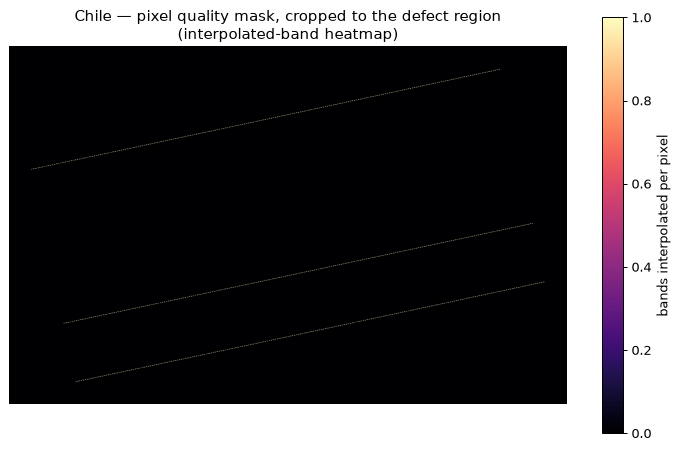

In [9]:
chile = next(p for p in scenes if "copper-mine" in p.name)
dm2 = tifffile.imread(str(chile / "data_mask.tiff"))
pq2 = tifffile.imread(str(chile / "pixel_quality_mask.tiff"))
valid2 = np.any(dm2 != 255, axis=-1)
vtot2 = int(valid2.sum())
nb2 = pq2.shape[2]

interp2 = int((pq2[valid2] == 1).sum())
print(f"Chile: {vtot2:,} valid pixels × {nb2} bands = {vtot2*nb2:,} band-pixels")
print(f"interpolated flags found:  {interp2:,}")
interpolated_pct = round(100 * interp2 / (vtot2 * nb2), 4)
print(f"→ interpolated_pct = 100 × {interp2:,} / {vtot2*nb2:,} = {interpolated_pct}%")

# per-band view — is any single band a full dropout?
per_band = [int((pq2[..., b][valid2] == 1).sum()) for b in range(nb2)]
print(f"bands with any interpolated pixels: {[i for i, c in enumerate(per_band) if c > 0]}")
print(f"full-band dropout (a band ~100% interpolated): {any(c >= vtot2 for c in per_band)}")

# visualize: count interpolated bands per pixel
# Naive full-scene downsampling (stride slicing) makes this defect invisible: it's a
# thin scan-line only ~900px tall in a ~9,200px-tall image, across just 3 of 23 bands
# — an every-Nth-pixel stride can skip every single defect pixel. Two fixes instead:
# 1) crop to the defect's actual bounding box before downsampling, so nothing is skipped
# 2) cap the colorbar at the real max (3 bands), not an assumed 0-1 range — otherwise
#    a value of "3" reads as barely-above-black on a scale that goes up to "23"
bad_rows, bad_cols = np.where((pq2 == 1).any(axis=-1))
pad = 200
r0, r1 = max(0, bad_rows.min() - pad), min(pq2.shape[0], bad_rows.max() + pad)
c0, c1 = max(0, bad_cols.min() - pad), min(pq2.shape[1], bad_cols.max() + pad)
crop = pq2[r0:r1, c0:c1, :]
f = max(1, crop.shape[1] // 1200)
heat = (crop[::f, ::f] == 1).sum(axis=-1)
print(f"\ncropped to defect bbox (+{pad}px pad): rows {r0}:{r1}, cols {c0}:{c1}")
print(f"heat value range in crop: {heat.min()} to {heat.max()} bands interpolated per pixel")

plt.figure(figsize=(10, 6))
im = plt.imshow(heat, cmap="magma", vmin=0, vmax=max(1, heat.max()))
plt.colorbar(im, label="bands interpolated per pixel")
plt.title("Chile — pixel quality mask, cropped to the defect region\n(interpolated-band heatmap)")
plt.axis("off")
plt.show()

---
## Localizing the defect — a real, band-specific sensor artifact

The heatmap above shows *that* some pixels are interpolated, but not *why* only
3 of 23 bands are affected, or whether they're scattered noise or one physical event.
Let's find out — this is exactly the kind of digging a PM would do before writing
an incident summary, not just reporting the aggregate `interpolated_pct` number.


In [10]:
# Which bands actually have interpolated pixels, and where do they sit spatially?
bad_bands = [b for b, c in enumerate(per_band) if c > 0]
print(f"bands with interpolated pixels: {bad_bands}  (out of {nb2} total)")
for b in bad_bands:
    print(f"  band {b}: {per_band[b]:,} interpolated pixels")

# Spatial footprint: are the flagged pixels clustered (one physical event) or scattered?
rows, cols = np.where(pq2[:, :, bad_bands[0]] == 1)
print(f"\nrow range:  {rows.min():,} - {rows.max():,}  (image height {pq2.shape[0]:,})")
print(f"col range:  {cols.min():,} - {cols.max():,}  (image width {pq2.shape[1]:,})")
print(f"row span:   {rows.max()-rows.min():,} px  |  col span: {cols.max()-cols.min():,} px")

row_frac = (rows.max() - rows.min()) / pq2.shape[0]
col_frac = (cols.max() - cols.min()) / pq2.shape[1]
print(f"\n→ confined to ~{row_frac*100:.0f}% of image height but spans ~{col_frac*100:.0f}% of image width:")
print("  the signature of a SCAN-LINE defect — a transient sensor glitch affecting")
print("  bands 13/15/16 for one stretch of the pushbroom sweep, not random noise")
print("  and not a permanently dead detector element (which would show up in every scene).")

bands with interpolated pixels: [13, 15, 16]  (out of 23 total)
  band 13: 9,620 interpolated pixels
  band 15: 9,626 interpolated pixels
  band 16: 9,625 interpolated pixels



row range:  6,901 - 7,805  (image height 9,181)
col range:  1,423 - 5,655  (image width 5,937)
row span:   904 px  |  col span: 4,232 px

→ confined to ~10% of image height but spans ~71% of image width:
  the signature of a SCAN-LINE defect — a transient sensor glitch affecting
  bands 13/15/16 for one stretch of the pushbroom sweep, not random noise
  and not a permanently dead detector element (which would show up in every scene).


---
## Seeing the band-13/15/16 defect in 3D

Same idea, but now the z-axis is the *real spectral band index* (0–22), and
we crop to the defect's actual row/col range so the thin scan-line doesn't get
lost after downsampling. The healthy footprint at band 0 is included as a
faint reference plane — everything above it that lights up is where a real
sensor reading was replaced with a software estimate.


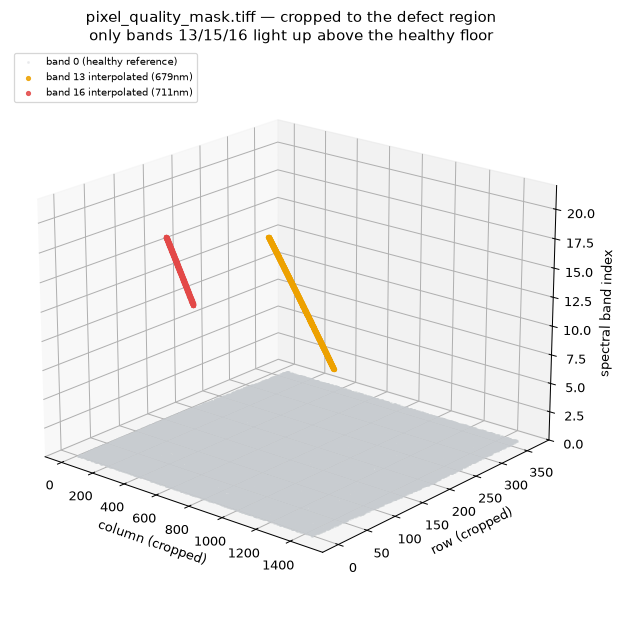

In [11]:
r0, r1 = rows.min() - 100, rows.max() + 100
c0, c1 = cols.min() - 100, cols.max() + 100
crop = pq2[max(r0,0):r1, max(c0,0):c1, :]
f3d2 = max(1, crop.shape[0] // 300)
crop_small = crop[::f3d2, ::f3d2, :]
Hc, Wc, Bc = crop_small.shape

yyc, xxc = np.meshgrid(np.arange(Hc), np.arange(Wc), indexing="ij")

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# healthy reference plane at band 0
valid0 = crop_small[:, :, 0] != 255
rng3 = np.random.default_rng(0)
keep0 = rng3.random(valid0.sum()) < 0.15
ax.scatter(xxc[valid0][keep0], yyc[valid0][keep0], np.zeros(keep0.sum()),
           c="#c8ccd0", s=2, alpha=0.25, depthshade=False, label="band 0 (healthy reference)")

band_colors = {13: "#eda100", 15: "#eb6834", 16: "#e34948"}
wl = {13: "679nm", 15: "699nm", 16: "711nm"}
for b in bad_bands:
    bad = crop_small[:, :, b] == 1
    if bad.any():
        ax.scatter(xxc[bad], yyc[bad], np.full(bad.sum(), b),
                   c=band_colors.get(b, "#e34948"), s=10, alpha=0.85,
                   depthshade=False, label=f"band {b} interpolated ({wl.get(b,'')})")

ax.set_xlabel("column (cropped)"); ax.set_ylabel("row (cropped)"); ax.set_zlabel("spectral band index")
ax.set_zlim(0, pq2.shape[2] - 1)
ax.set_title("pixel_quality_mask.tiff — cropped to the defect region\nonly bands 13/15/16 light up above the healthy floor")
ax.legend(loc="upper left", fontsize=8)
ax.view_init(elev=20, azim=-50)
plt.tight_layout(); plt.show()

---
## Seeing the defect at true scale — the whole scene, all bands

The plot above zoomed into the defect so it's legible, but that crop makes it
look bigger than it is. This one uses the *entire* scene, all 23 bands, no
cropping — the grey haze is 23 stacked planes of healthy data (each plane is
one spectral band), and the dark specks trace the outline of the scan strip
(NoData outside it). Only a handful of bright points break through: that's
the true proportion of bad data to good — 28,871 flagged band-pixels out of
roughly 840 million.


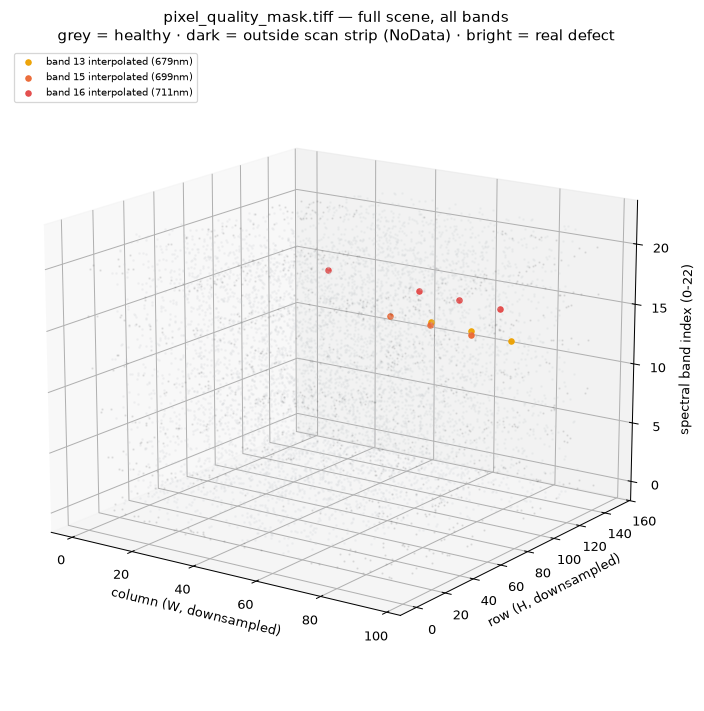

In [12]:
f_full = max(1, pq2.shape[0] // 150)
small = pq2[::f_full, ::f_full, :]
H, W, B = small.shape
yy, xx = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')
rng_full = np.random.default_rng(0)
for b in range(B):
    layer = small[:, :, b]
    healthy = layer == 0
    ys, xs = yy[healthy], xx[healthy]
    if len(ys):
        keep = rng_full.random(len(ys)) < 0.03
        ax.scatter(xs[keep], ys[keep], np.full(keep.sum(), b), c='#c8ccd0', s=1.5, alpha=0.12, depthshade=False)
for b in range(0, B, 4):
    layer = small[:, :, b]
    nodata = layer == 255
    ys, xs = yy[nodata], xx[nodata]
    if len(ys):
        keep = rng_full.random(len(ys)) < 0.03
        ax.scatter(xs[keep], ys[keep], np.full(keep.sum(), b), c='#2a2a2a', s=1, alpha=0.08, depthshade=False)
band_colors = {13: '#eda100', 15: '#eb6834', 16: '#e34948'}
wl = {13: '679nm', 15: '699nm', 16: '711nm'}
for b in bad_bands:
    layer = small[:, :, b]
    bad = layer == 1
    ys, xs = yy[bad], xx[bad]
    if len(ys):
        ax.scatter(xs, ys, np.full(len(ys), b), c=band_colors.get(b, '#e34948'), s=18, alpha=0.95, depthshade=False, label=f'band {b} interpolated ({wl.get(b,"")})')
ax.set_xlabel('column (W, downsampled)'); ax.set_ylabel('row (H, downsampled)'); ax.set_zlabel('spectral band index (0-22)')
ax.set_title('pixel_quality_mask.tiff — full scene, all bands\ngrey = healthy · dark = outside scan strip (NoData) · bright = real defect')
ax.legend(loc='upper left', fontsize=8)
ax.view_init(elev=16, azim=-55)
plt.tight_layout(); plt.show()

---
## All four metrics for all three scenes

Now run the same four calculations over every scene and compare. This is the
exact table `qa_rules.py` works from.

In [13]:
def metrics_for(folder):
    d = DATA / folder
    dm_ = tifffile.imread(str(d / "data_mask.tiff"))
    pq_ = tifffile.imread(str(d / "pixel_quality_mask.tiff"))
    v_ = np.any(dm_ != 255, axis=-1); vt = int(v_.sum())
    cl = (dm_[..., 1] == 1) & v_; hz = (dm_[..., 2] == 1) & v_
    pqv = np.any(pq_ != 255, axis=-1)
    return {
        "bands": pq_.shape[2],
        "cloud_or_haze_pct": round(100 * (cl | hz).sum() / vt, 2),
        "mask_cov_pct": round(100 * (v_ & pqv).sum() / vt, 2),
        "interp_pct": round(100 * (pq_[v_] == 1).sum() / (vt * pq_.shape[2]), 4),
        "valid_pct": round(100 * vt / v_.size, 2),
    }

print(f"{'scene':<40s} {'bands':>5s} {'cloud+haze%':>11s} {'maskcov%':>8s} {'interp%':>8s} {'valid%':>6s}")
for p in scenes:
    m = metrics_for(p.name)
    print(f"{p.name:<40s} {m['bands']:>5d} {m['cloud_or_haze_pct']:>11.2f} {m['mask_cov_pct']:>8.2f} {m['interp_pct']:>8.4f} {m['valid_pct']:>6.2f}")

scene                                    bands cloud+haze% maskcov%  interp% valid%


01-clean-cropfield-australia                31        0.00   100.00   0.0000  47.05


02-wildfire-smoke-saskatchewan              31       62.30   100.00   0.0000  59.96


03-copper-mine-chile                        23        0.00   100.00   0.0034  67.10


---
## The rules — `agent/rules.json`

None of this logic is hardcoded: `qa_rules.py` reads the PRD's rules from
`rules.json`. Notice the shape of every rule — `levels` (which processing
level it applies to), `category`, `routing` (retry vs escalate), and
mechanical `checks` (metric + operator + threshold).

In [14]:
rules = json.loads((ROOT / "agent" / "rules.json").read_text())
print("max_retries:", rules["max_retries"])
print("platforms (expected bands):", json.dumps(rules["platforms"]))
print()
for r in rules["rules"]:
    checks = "; ".join(
        f"{c['metric']} {c.get('op','')} {c.get('threshold', c.get('threshold_ref'))}"
        for c in r["checks"]
    )
    print(f"{r['id']:5s} [{','.join(r['levels']):10s}] {r['category']:10s} → {r['routing']:8s} | {checks}")

max_retries: 2
platforms (expected bands): {"Dragonette-001": {"expected_bands": 23}, "Dragonette-002": {"expected_bands": 31}, "Dragonette-003": {"expected_bands": 31}, "Dragonette-004": {"expected_bands": 31}}

QA-1  [L1B       ] INCOMPLETE → escalate | band_count lt platform.expected_bands; aoi_coverage_pct lt 95
QA-2  [L1B,L2A   ] MASK_GAP   → escalate | quality_mask_coverage_pct lt 100
QA-3  [L1B,L2A   ] CLOUD      → retry    | cloud_or_haze_pct gt 40
QA-4  [L1B,L2A   ] SENSOR     → escalate | interpolated_pct gt 2; full_band_dropout eq True; max_high_value_band_interpolated_pct gt 0.1
QA-5  [L1B,L2A   ] GEOM       → retry    | geolocation_rmse_px gt 1; coreg_offset_px gt 0.5
QA-6  [L2A       ] RADIO      → retry    | reflectance_out_of_bounds_pct gt 0.5
QA-7  [L2A       ] RADIO      → escalate | band_corr_mean lt 0.7; band_corr_min_tile lt 0.5


---
## Run the *real* QA engine and verify

Now we hand our metrics to the same modules the pipeline actually runs
(`analyze_scene.py` → `qa_rules.py`) and check the decisions match what's
already committed in `agent/decisions.json`. This is the moment "our
calculations" become "the committed decision".

In [15]:
from analyze_scene import compute_metrics
from qa_rules import evaluate_rule, decide

payload = json.loads((ROOT / "agent" / "decisions.json").read_text())
expected = {s["scene_id"]: s["decision"] for s in payload["scenes"]}

for p in scenes:
    info, metrics = compute_metrics(p)
    platform = rules["platforms"].get(info["platform"], {})
    scene = {"processing_level": info["processing_level"], "platform_spec": platform,
             "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False}
    evals = [evaluate_rule(r, metrics, scene) for r in rules["rules"]]
    dec = decide(evals, metrics, scene)
    match = "✓ matches decisions.json" if dec["decision"] == expected.get(info["scene_id"]) else "✗ MISMATCH"
    print(info["scene_id"])
    print(f"  → {dec['decision'].upper():9s} category={dec['failure_category']} rule={dec['fired_rule']} "
          f"retries={dec['retry_count']}   {match}")
    print(f"  reasoning: {dec['reasoning']}")
    print()

wyvern_dragonette-003_20250319T000402_d5ebab06_l2a
  → PASS      category=None rule=None retries=0   ✓ matches decisions.json
  reasoning: No QA rule failed. Scene is CLEAN.



wyvern_dragonette-003_20250531T173810_56fca26e_l2a
  → RETRY     category=CLOUD rule=QA-3 retries=1   ✓ matches decisions.json
  reasoning: Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=40 → FAIL



wyvern_dragonette-001_20240620T145630_2d5d0eef_l2a
  → PASS      category=None rule=None retries=0   ✓ matches decisions.json
  reasoning: No QA rule failed. Scene is CLEAN.



---
## Three rule refinements from the copper-mine finding

Recall the scan-line defect discovered earlier (bands 13/15/16 = 679/699/711nm),
and that QA-7's scene-wide `band_corr_mean` (0.969) never noticed it — averaged
over the whole scene, a defect confined to ~10% of the image barely moves the
number. That gap motivated three real rule changes:

1. **QA-4 becomes band-aware** — a stricter ceiling (0.1%, vs. the 2% scene-wide
   average) applies to the worst single *red-edge* band (711–782nm) specifically,
   since that's the sensor's most information-dense region. This also fixed
   a real bug: QA-4 was scoped to L1B only, so it silently never fired on any of
   our L2A scenes — widened to L2A.
2. **QA-7 becomes region-aware** — in addition to the scene-wide mean, correlation
   is now also computed per spatial tile (8×8 grid); the *worst* tile is checked
   against a looser threshold (0.5, vs. 0.7 scene-wide), so a small tile's
   naturally noisier estimate isn't over-penalized.
3. **Partial delivery** — a scene can now reach `delivery_ready_partial`: ship
   with specific defective bands excluded, rather than the whole scene held back
   for a defect in 1 of 23 bands. Strictly opt-in and only for band-isolable QA-4
   failures — never for QA-3/5/6/7, which aren't confined to specific bands.

`compute_metrics()`/`qa_rules.py` already implement all three — the cell above
(§ "Run the real QA engine") is already running this new logic. Let's look
at the new metrics directly for the copper-mine scene.


In [16]:
chile_info, chile_metrics = compute_metrics(chile)

print("QA-4 — sensor artifact (PRD §3):")
print(f"  interpolated_pct (scene-wide):            {chile_metrics['interpolated_pct']}%  (threshold 2%)")
print(f"  max_high_value_band_interpolated_pct:     {chile_metrics['max_high_value_band_interpolated_pct']}%  (threshold 0.1%, red-edge bands only)")
print(f"  → band 16 (711nm) is the worst red-edge band; still well under the\n"
      f"    per-band ceiling, so this scene passes QA-4.\n")

chile_platform = rules["platforms"].get(chile_info["platform"], {})
chile_scene = {"processing_level": chile_info["processing_level"], "platform_spec": chile_platform,
               "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False,
               "partial_delivery_opt_in": False}
chile_evals = [evaluate_rule(r, chile_metrics, chile_scene) for r in rules["rules"]]
chile_dec = decide(chile_evals, chile_metrics, chile_scene)

print("Delivery-readiness fields (PRD §5):")
print(f"  delivery_ready:         {chile_dec['delivery_ready']}")
print(f"  delivery_ready_partial: {chile_dec['delivery_ready_partial']}")
print(f"  excluded_bands:         {chile_dec['excluded_bands']}")
print(f"  note: {chile_dec['delivery_ready_note']}")
print("  → this scene passes outright (QA-4 didn't fail), so partial delivery\n"
      "    logic doesn't engage here — it only activates when QA-4's band-isolable\n"
      "    check is the SOLE failure. Included to show the fields exist and read\n"
      "    correctly even in the non-triggering case.")


QA-4 — sensor artifact (PRD §3):
  interpolated_pct (scene-wide):            0.0034%  (threshold 2%)
  max_high_value_band_interpolated_pct:     0.0263%  (threshold 0.1%, red-edge bands only)
  → band 16 (711nm) is the worst red-edge band; still well under the
    per-band ceiling, so this scene passes QA-4.

Delivery-readiness fields (PRD §5):
  delivery_ready:         True
  delivery_ready_partial: False
  excluded_bands:         []
  note: Passed on all assessable rules and meets PRD section 6 conditions.
  → this scene passes outright (QA-4 didn't fail), so partial delivery
    logic doesn't engage here — it only activates when QA-4's band-isolable
    check is the SOLE failure. Included to show the fields exist and read
    correctly even in the non-triggering case.


---
## Experiment — break the rules, watch the decision flip

The Saskatchewan scene has 62.3% cloud+smoke. QA-3's threshold is 40% — so it
retries. What if the threshold were different? **Drag the slider.** This is
the whole job in miniature: someone sets a threshold, the pipeline reacts,
and you have to live with the consequences.

- Drag it **up to 70%**: Saskatchewan now *passes* — 62.3% of the scene is
  smoke and we'd ship it. Why is that dangerous?
- Drag it **down to 20%**: even the *clean* scenes would retry — nothing ever
  ships.
- The real lesson: a threshold isn't "correct" in the abstract; it's a
  business decision about how much unusable imagery you're willing to deliver.

In [17]:
from ipywidgets import interact, FloatSlider
import os

sk = next(p for p in scenes if "wildfire" in p.name)
sk_info, sk_metrics = compute_metrics(sk)
sk_scene = {"processing_level": "L2A",
            "platform_spec": rules["platforms"][sk_info["platform"]],
            "retry_count": 0, "max_retries": rules["max_retries"], "superseded": False}

def qa3_experiment(threshold):
    rules2 = json.loads((ROOT / "agent" / "rules.json").read_text())
    for r in rules2["rules"]:
        if r["id"] == "QA-3":
            r["checks"][0]["threshold"] = threshold
    evals = [evaluate_rule(r, sk_metrics, sk_scene) for r in rules2["rules"]]
    dec = decide(evals, sk_metrics, sk_scene)
    print(f"Saskatchewan cloud_or_haze = {sk_metrics['cloud_or_haze_pct']}%   |   "
          f"QA-3 threshold = {threshold}%")
    print(f"→ decision: {dec['decision'].upper()}   ({dec['reasoning']})")

# The live slider only works in a running Jupyter session (ipywidgets needs a
# comm channel to the frontend) — it hangs headless `jupyter nbconvert --execute`.
# Skip it automatically when running non-interactively; run a few thresholds by
# hand instead so the notebook still shows real output when exported.
if os.environ.get("JPY_PARENT_PID") and not os.environ.get("NBCONVERT_EXECUTE"):
    interact(qa3_experiment, threshold=FloatSlider(min=0, max=90, step=1, value=40,
                                                   description="QA-3 threshold %"));
else:
    print("(non-interactive run — showing a few threshold values instead of the live slider)\n")
    for t in [20, 40, 62.3, 70, 90]:
        qa3_experiment(t)
        print()


(non-interactive run — showing a few threshold values instead of the live slider)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 threshold = 20%
→ decision: RETRY   (Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=20 → FAIL)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 threshold = 40%
→ decision: RETRY   (Rule QA-3 (cloud_obstruction) fired: cloud_or_haze_pct=62.3 gt threshold=40 → FAIL)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 threshold = 62.3%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 threshold = 70%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)

Saskatchewan cloud_or_haze = 62.3%   |   QA-3 threshold = 90%
→ decision: PASS   (No QA rule failed. Scene is CLEAN.)



---
## Now you try

1. **Add the 4th scene.** There's a `data/jasper-wildfire/` folder on disk
   (the Jasper, Alberta wildfire — I evaluated it and it was 99.5% clear, so
   it wasn't used in the final three). Copy it into the expected shape
   (`stac_metadata.json` + masks) and re-run the "all metrics" cell — or ask
   me to wire it up and you predict its decision first.
2. **Change the interpolated threshold** (QA-4, currently 2%). Chile has
   0.0034% — could any realistic threshold make it fail? (Note QA-4 is
   L1B-gated: it doesn't even apply at L2A. Why do you think the PRD gates it?)
3. **Re-run `agent/triage_agent.py`** after your changes and see
   `agent/decisions.json` + the reasoning logs update. Then rebuild the
   dashboard: `python dashboard/build_data.py`.
4. **Explain out loud** (this is the real test): why does Saskatchewan retry
   but not escalate? Why does the union matter for cloud+haze? What does the
   "valid footprint" protect us from?

---
## Summary — what you should now be able to explain

- What `data_mask.tiff` (4 bands) and `pixel_quality_mask.tiff` (23/31 bands)
  contain and what `1` / `0` / `255` mean in each.
- Why every metric is computed over the **valid footprint**.
- Exactly how the four metrics are computed, with the denominators.
- How `rules.json` turns the PRD into mechanical checks, and why
  **fixable → retry, unfixable → escalate**.
- Where the committed decisions come from — and that they're reproducible from
  the files in `data/` with the code in `agent/`.